# Imports

In [1]:
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from methods.bcgd_gauss_southwell import gs_bcgd
from methods.bcgd_randomized import randomized_bcgd
from methods.gradient_descent import gradient_descent
from methods.utils.accuracy import accuracy
from methods.utils.block_size import block_step_size
from methods.utils.gradient import MultiLogisticRegressionOracle, CachedMultiLogisticRegressionOracle
from methods.utils.results import accuracy_vs_CPU

rng = np.random.default_rng(seed=42) # Turnoff or modify if no seeding will be used.

I0000 00:00:1777306704.271349   10801 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1777306704.346024   10801 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1777306705.894898   10801 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Data Loading

## Synthetic Data

In [2]:
n_categories = 50
n_features = 500
n_examples = 1000

syntetic_features = rng.random((n_examples, n_features))
X = rng.random((n_features, n_categories))
E = rng.random((n_examples, n_categories))

transformation = np.dot(syntetic_features,X) + E
syntetic_labels = np.argmax(transformation, axis= 1)

syntetic_test_features = rng.random((n_examples, n_features))
test_transformation = np.dot(syntetic_features,X) + E
syntetic_test_labels = np.argmax(test_transformation, axis= 1)

syntetic_data = {
    "n_categories": n_categories,
    "n_features": n_features,
    "train_features": syntetic_features,
    "train_labels": syntetic_labels,
    "test_features": syntetic_test_features,
    "test_labels": syntetic_test_labels,
    "tolerance": 1.0,
}

## MNIST Dataset

In [21]:
n_components = 50
(mnist_features, mnist_labels), (mnist_features_test, mnist_labels_test) = mnist.load_data()

mnist_features = mnist_features.reshape((mnist_features.shape[0],-1))
mnist_features_test = mnist_features_test.reshape((mnist_features_test.shape[0],-1))

scaler = StandardScaler()
pca = PCA(n_components=n_components)

mnist_reduced_features = scaler.fit_transform(mnist_features)
mnist_reduced_features = pca.fit_transform(mnist_reduced_features)

mnist_reduced_features_test = scaler.transform(mnist_features_test)
mnist_reduced_features_test = pca.transform(mnist_reduced_features_test)

mnist_data = {
    "n_categories": 10,
    "n_features": n_components,
    "train_features": mnist_reduced_features,
    "train_labels": mnist_labels,
    "test_features": mnist_reduced_features_test,
    "test_labels": mnist_labels_test,
    "tolerance": 1e-3,
}

## Bloodcell Dataset

np.float64(1.286130266897922e-05)

# Method Calls
This section is for implementing all the methods that will be used for generating graphs or any other types of solutions

In [22]:
active_data = mnist_data

#calculated step sizes
step_sizes = block_step_size(active_data["train_features"])
avg_step_size = np.average(step_sizes)

oracle = MultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])
cached_oracle = CachedMultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])

## Gradient Descent

In [23]:
gradient_descent_results = gradient_descent(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    avg_step_size,  # Reduced step size to prevent NaN
    tol=active_data["tolerance"],
    debug=True,
)

Iteration 0: Loss = 53563.486809930764, sequential distance: 2.2221176129033777, Accuracy = 0.7274
Iteration 500: Loss = 20954.52041834843, sequential distance: 0.0013677798938791998, Accuracy = 0.8996666666666666


In [24]:
gradient_descent_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gradient_descent_results["history"]
]

accuracy(active_data["test_features"],active_data["test_labels"], gradient_descent_results["x_k"])

np.float64(0.8997)

## BCGD Randomized

In [25]:
randomized_bcgd_results = randomized_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    step_sizes,
    tol=active_data["tolerance"],
    debug=True,
)

iteration: 0, sequential distance: 0.05239755294021641, loss: 138053.9884313322
accuracy: 0.11603333333333334
iteration: 500, sequential distance: 0.009564966142895592, loss: 29158.141225486645
accuracy: 0.8695166666666667
iteration: 1000, sequential distance: 0.00349260717257651, loss: 25180.61045387975
accuracy: 0.882
iteration: 1500, sequential distance: 0.003530010760244284, loss: 23653.430301048444
accuracy: 0.8871833333333333


In [26]:
randomized_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in randomized_bcgd_results["history"]
]

accuracy(active_data["test_features"],active_data["test_labels"], randomized_bcgd_results["x_k"])

np.float64(0.8936)

## Gauss-Southwell BCGD

In [27]:
gs_bcgd_results = gs_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    cached_oracle,
    step_sizes,
    tol=active_data["tolerance"],
    debug=True,
)

iteration: 0, selected_block: 0, sequential distance: 0.1474055836732519, loss: 127863.014315
accuracy: 20.63%
iteration: 500, selected_block: 7, sequential distance: 0.0057982282465339685, loss: 26008.819531
accuracy: 87.69%


In [28]:
gs_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gs_bcgd_results["history"]
]

accuracy(active_data["test_features"],active_data["test_labels"], gs_bcgd_results["x_k"])

np.float64(0.8888)

In [10]:
accuracy(active_data["train_features"],active_data["train_labels"], gs_bcgd_results["x_k"])

np.float64(1.0)

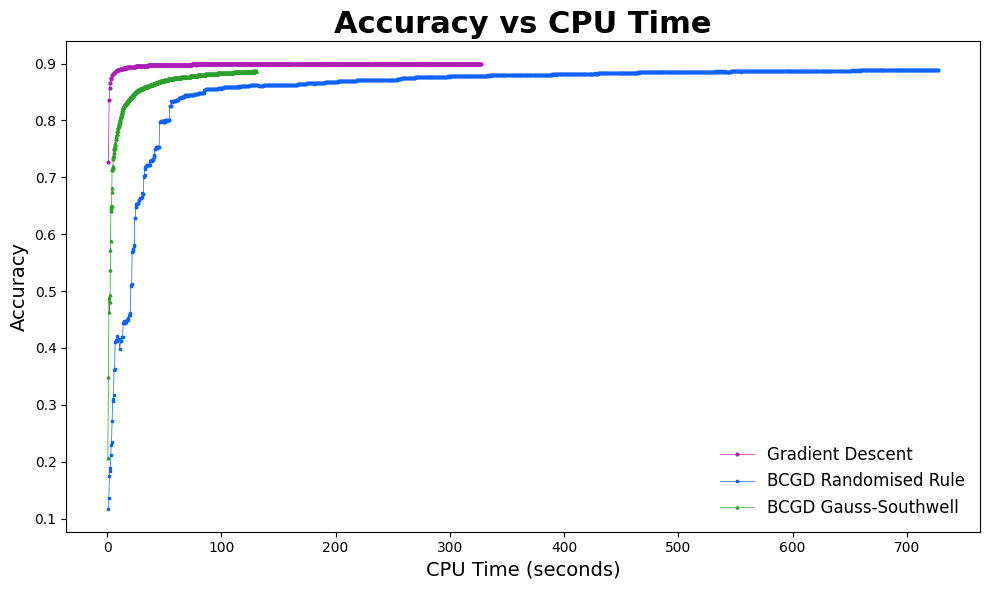

In [29]:
plotting_data = {
    "Gradient Descent": (gradient_descent_results["times"], gradient_descent_results["accuracies"]),
    "BCGD Randomised Rule": (randomized_bcgd_results["times"], randomized_bcgd_results["accuracies"]),
    "BCGD Gauss-Southwell": (gs_bcgd_results["times"], gs_bcgd_results["accuracies"]),
}

accuracy_vs_CPU(plotting_data)